# Net pay and reservoir zones

Net pay is the bottom line of a single-well interpretation: of the whole drilled interval, how
much is actually reservoir, and of that, how much holds producible hydrocarbons. It's built from
three cutoffs applied in sequence, clay volume (is it reservoir rock?), porosity (does it hold
enough?), and water saturation (is it hydrocarbon, not water?). Each cutoff narrows the count.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
WELL = REPO / "petrophys" / "data" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
import numpy as np
well = read_las(WELL)
run_dynamic_workflow(well, lithology="clastic")        # writes NET_ROCK, NET_RES, NET_PAY
step = well.step or 0.15
for flag in ("NET_ROCK", "NET_RES", "NET_PAY"):
    print(f"{flag:9s}: {np.nansum(well.get(flag).data > 0.5) * step:6.1f} m")

NET_ROCK :  993.0 m
NET_RES  :  469.1 m
NET_PAY  :   30.2 m


Each line is thinner than the one above it: net rock survives the clay cutoff, net reservoir
also clears the porosity cutoff, net pay also clears the saturation cutoff. One detail worth
knowing, washed-out hole is excluded from net pay, because where the borehole has caved the
density and neutron readings are unreliable and you can't honestly certify pay there. The flags
plotted against the interpretation make the surviving intervals obvious:

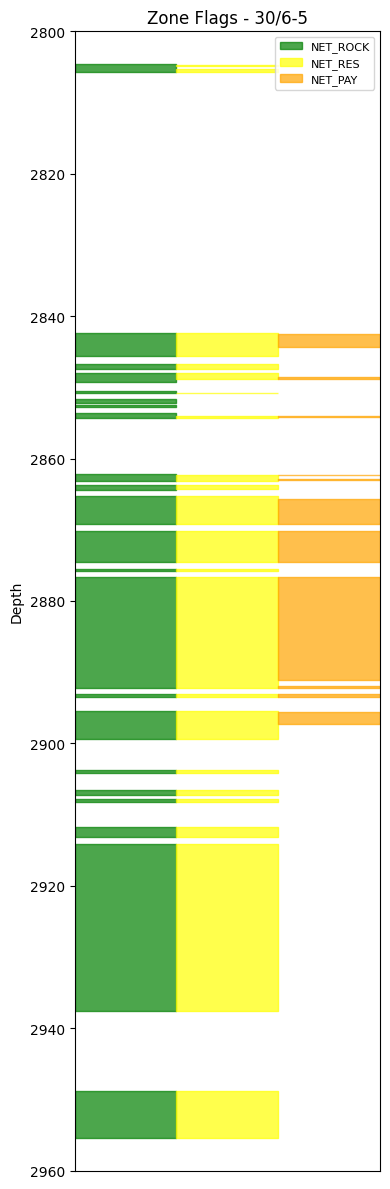

In [2]:
from petrophys.visualization import plot_zone_flags
plot_zone_flags(well, flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"], depth_range=(2800, 2960));

The cutoffs aren't universal, they depend on the play, the fluid, and what's economic, so
treat the defaults as a starting point and set your own. The *core calibration* deep dive checks
the net-pay flags against wells the regulator confirmed as dry or producing.